# Homework 2 – Classification

In this exercise you will use scikit-learn, a popular machine learning package in Python, to train and tune a classifier. One of its major advantages is that all classifiers (and linear models) follow the same API, making it straightforward to experiment with different methods. In this assignment, we will apply a classification technique (e.g., logistic regression) that represents common challenges and workflows you will encounter in predictive modeling.

⸻

## Dataset 1

The dataset you will be using is the Statlog (German Credit Data) dataset from the UCI Machine Learning Repository.
This dataset contains information about individuals applying for credit and whether they are considered “good” or “bad” credit risks based on demographic and financial attributes.

There are two data files: “Statlog_training.csv” and “Statlog_Xtest.csv.”
Both files have the following fields, except the label (“CreditRisk”) which is not available in “Statlog_Xtest.csv.”

There is an additional file, “Dataset 1 Variable Information.pdf,” which explains the meanings of all categorical variable codes. This file is optional, and you do not need to know the specific code mappings (e.g., A11, A12, etc.) to complete the homework. However, if you are interested in understanding the categories behind these codes, feel free to consult the file.

Features
- Attribute1 – Status of existing checking account:
Categorical variable indicating the status of the applicant’s checking account (e.g., “no checking account,” “<0 DM,” “0–200 DM,” “≥200 DM”).
- Attribute2 – Duration:
Duration of the credit in months (integer).
- Attribute3 – Credit history:
Categorical variable describing the applicant’s past credit history (e.g., “no credits taken,” “all credits paid back duly,” “critical account”).
- Attribute4 – Purpose:
Categorical variable describing the purpose of the credit (e.g., “car,” “furniture,” “education,” “business,” etc.).
- Attribute5 – Credit amount:
The total amount of credit granted (integer, in Deutsche Marks).
- Attribute6 – Savings account/bonds:
Categorical variable indicating the status of the applicant’s savings or bonds (e.g., “<100 DM,” “100–500 DM,” “≥1000 DM,” or “unknown”).
- Attribute7 – Present employment since:
Categorical variable indicating how long the applicant has been employed at their current job (e.g., “unemployed,” “<1 year,” “1–4 years,” “4–7 years,” “≥7 years”).
- Attribute8 – Installment rate (% of disposable income):
Integer variable representing the installment rate as a percentage of disposable income.
- Attribute9 – Personal status and sex:
Categorical variable combining marital status and gender (e.g., “male, single,” “female, divorced,” etc.).
- Attribute10 – Other debtors/guarantors:
Categorical variable indicating whether there are other debtors or guarantors (e.g., “none,” “co-applicant,” “guarantor”).
- Attribute11 – Present residence since:
Integer variable showing how long the applicant has lived at their current residence (in years).
- Attribute12 – Property:
Categorical variable describing the applicant’s property ownership (e.g., “real estate,” “life insurance,” “car,” “unknown”).
- Attribute13 – Age:
Applicant’s age in years (integer).
- Attribute14 – Other installment plans:
Categorical variable describing whether the applicant has other installment plans (e.g., “bank,” “stores,” “none”).
- Attribute15 – Housing:
Categorical variable describing the applicant’s housing situation (e.g., “own,” “rent,” “free”).
- Attribute16 – Number of existing credits at this bank:
Integer variable representing how many existing credits the applicant currently has at the bank.
- Attribute17 – Job:
Categorical variable describing the applicant’s occupation (e.g., “unskilled and non-resident,” “skilled,” “management/self-employed”).
- Attribute18 – Number of people being liable to provide maintenance for:
Integer variable indicating the number of dependents financially supported by the applicant.
- Attribute19 – Telephone:
Binary variable indicating whether the applicant has a registered telephone (1 = yes, 0 = no).
- Attribute20 – Foreign worker:
Binary variable indicating whether the applicant is a foreign worker (1 = yes, 0 = no).

⸻

Target

CreditRisk:
Binary variable indicating the creditworthiness of the applicant:
- 1 = Good
- 2 = Bad

⸻

Files
- Statlog_training.csv: Training set containing all features and the target CreditRisk.
- Statlog_Xtest.csv: Test set containing only the features (no target column).
- Dataset 1 Variable Information.pdf: (optional) Explanation of all variables.

⸻

Goal

Predict the CreditRisk (good or bad credit) for each applicant based on their demographic and financial attributes.


In [1]:
import numpy as np
import pandas as pd
import io
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder



In [2]:
# Load your training data set

df_stat_training = pd.read_csv('statlog_train.csv')
df_stat_test = pd.read_csv('statlog_Xtest.csv')

# class is the credit risk identifier in training data


In [3]:
# Split training data into X and y

# training class
y_stat_train = df_stat_training['class']

# features
x_stat_train = df_stat_training.drop('class', axis=1)

## Standardization and One-hot Encoding

Standardize the continuous features and convert categorical variables into dummy variables.<br>
Note: The Statlog dataset contains both categorical and numerical attributes. Categorical attributes (like Attribute1, Attribute3, Attribute4, etc.) should be one-hot encoded, while numerical attributes (like Attribute2, Attribute5, Attribute8, etc.) should be standardized.

Standardization and one-hot encoding for training set and test set

In [5]:
# Load test data set

# select column names by data type -- 'number' includes floats and integers
numerical_cols = x_stat_train.select_dtypes(include=['number']).columns.tolist()

# 'object' and 'category' for pandas types
categorical_cols = x_stat_train.select_dtypes(include=['object', 'category']).columns.tolist()

# double check!
print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['Attribute2', 'Attribute5', 'Attribute8', 'Attribute11', 'Attribute13', 'Attribute16', 'Attribute18']
Categorical columns: ['Attribute1', 'Attribute3', 'Attribute4', 'Attribute6', 'Attribute7', 'Attribute9', 'Attribute10', 'Attribute12', 'Attribute14', 'Attribute15', 'Attribute17', 'Attribute19', 'Attribute20']


In [6]:
#standardization and one-hot encoding 

# create transformer
preprocessor = ColumnTransformer(
    transformers=[
        # (name, transformer, columns_to_apply_to)
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)




**Splitting training data into training and validation set (70:30 ratio) (the code has been provided)**

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(x_stat_train, y_stat_train, test_size=0.3, random_state=42)

preprocessor.fit(X_train)

# 1. Transform the Training set
X_train_processed = preprocessor.transform(X_train)

# 2. Transform the Validation set
X_val_processed = preprocessor.transform(X_val)

# 3. Transform the External Test set
# (Ensure this dataframe has the same column names as x_stat_train)
X_test_processed = preprocessor.transform(df_stat_test)



Print the shape of X_train, y_train, X_val

In [8]:
print(X_train_processed.shape)
print(X_val_processed.shape)
print(X_test_processed.shape)

(560, 48)
(240, 48)
(200, 48)


## Logistic Regression

As previously mentioned, the scikit-learn classification API makes it easy to train a classifier. 


Use LogisticRegression from sklearn.linear_model to make a logistic regression classifier.

In [10]:
from sklearn.linear_model import LogisticRegression

In [11]:
# First, initialize the classifier with default parameters
# then fit the classifier on training data and labels

### WRITE CODE HERE ###

# 1. Initialize the classifier with default parameters
log_reg = LogisticRegression()

# 2. Fit the classifier on the training data and labels
log_reg.fit(X_train_processed, y_train)




,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [ ]:
# If there is any ConvergenceWarning, increase the number of iterations. (Let max_iter = 200)
### WRITE CODE HERE ###

# none?


In [12]:
# predict the output for validation dataset
### WRITE CODE HERE

# Use the trained model to predict labels for the validation set
y_val_pred = log_reg.predict(X_val_processed)

# Optional: Print the first 5 predictions to see what they look like
print("First 5 predictions:", y_val_pred[:5])


First 5 predictions: [2 2 1 1 1]


Implement my_precision(), my_recall(), my_accuracy() by yourselves

In [33]:
def my_precision(y, y_preds): #TP/(TP+FP)
    # Define which class we care about (1 = Good, 2 = Bad)
    # Let's calculate precision for predicting "Good Credit" (1)
    pos_label = 1
    
    # Calculate True Positives (TP)
    # Correctly predicted '1' (Actual is 1 AND Prediction is 1)
    tp = sum((y == pos_label) & (y_preds == pos_label))
    
    # Calculate False Positives (FP)
    # Incorrectly predicted '1' (Actual is NOT 1, but Prediction IS 1)
    fp = sum((y != pos_label) & (y_preds == pos_label))
    
    # Calculate Precision
    # Handle division by zero just in case the model never predicts '1'
    if (tp + fp) == 0:
        return 0.0
    
    return tp / (tp + fp)

def my_recall(y, y_preds): #TP/(TP+FN)
    pos_label = 1
    
    # 1. Calculate True Positives (TP)
    # Correctly predicted '1'
    tp = sum((y == pos_label) & (y_preds == pos_label))
    
    # 2. Calculate False Negatives (FN)
    # Missed opportunities: Actual was '1', but we predicted '2'
    fn = sum((y == pos_label) & (y_preds != pos_label))
    
    # 3. Calculate Recall
    # Denominator (TP + FN) is simply the Total Count of Actual Positives
    if (tp + fn) == 0:
        return 0.0
        
    return tp / (tp + fn)


def my_accuracy(y, y_preds): #(TP+TN)/(TP+FP+FN+TN)
    # 1. Count Correct Predictions (TP + TN)
    # This checks where y matches y_preds exactly
    correct_count = sum(y == y_preds)
    
    # 2. Get Total Count (TP + FP + FN + TN)
    total_count = len(y)
    
    # 3. Calculate Accuracy
    if total_count == 0:
        return 0.0
        
    return correct_count / total_count

Use your above functions to compute precision, recall, and accuracy of your model on validation set:

In [35]:
### WRITE CODE HERE

precision_value = my_precision(y_val, y_val_pred)
print(f"My Precision Score: {precision_value:.4f}")

rec = my_recall(y_val, y_val_pred)
acc = my_accuracy(y_val, y_val_pred)

print(f"My Recall:   {rec:.4f}")
print(f"My Accuracy: {acc:.4f}")



My Precision Score: 0.8402
My Recall:   0.7978
My Accuracy: 0.7375


Q. Accuracy<br>
Ans - .7375

Q. Precision<br>
Ans - .8402

Q. Recall<br>
Ans - .7978

Q. Which metric (accuracy, precision, recall) is more appropriate and in what cases? Will there be scenarios where it is better to use precision than accuracy? Explain. <br>
Ans -   Precision is the better metric when the cost of a False Positive is very high. In  credit risk context, if approving a customer who eventually defaults (False Positive) causes the bank to lose a massive amount of money, you should prioritize Precision; this ensures that when the model predicts "Good," it is highly confident, even if that means rejecting some decent customers to play it safe.

Q. Which metric is suitable in this case? <br>
Ans - High Precision means: "When we predict a customer is Good, we are very confident they won't default."

### ROC curve

Use roc_Curve from sklearn.metrics and use matplotlib.pyplot to plot the ROC curve. Use validation set to make predictions and to draw ROC curve.

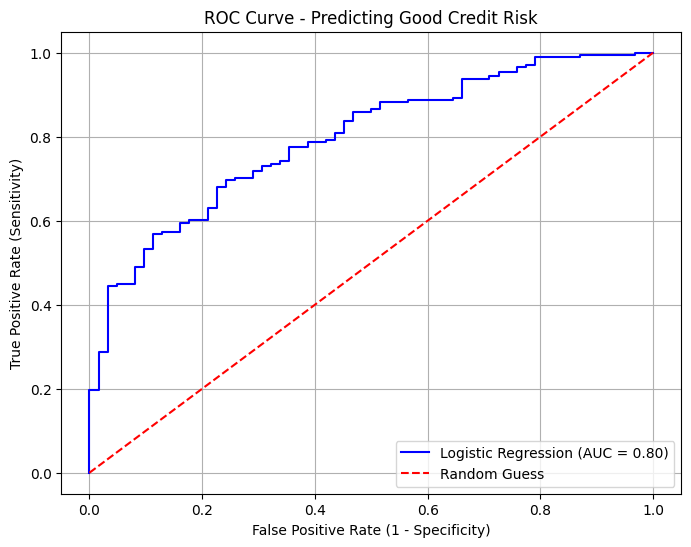

In [36]:
# Plot the ROC curve by giving appropriate names for title and axes. 
from sklearn.metrics import roc_curve
import sklearn.metrics as metrics
import matplotlib.pyplot as plt

# 1. Get the probabilities for the Positive Class (Class 1 = Good Credit)
# log_reg.classes_ is typically sorted [1, 2], so index 0 is Class 1.
y_pred_proba = log_reg.predict_proba(X_val_processed)[:, 0]

# 2. Calculate FPR, TPR, and Thresholds
# pos_label=1 ensures we are treating "Good Credit" as the positive case
fpr, tpr, thresholds = metrics.roc_curve(y_val, y_pred_proba, pos_label=1)

# 3. Calculate AUC (Area Under Curve) Score
auc_score = metrics.auc(fpr, tpr)

# 4. Plot the ROC Curve
plt.figure(figsize=(8, 6))

# Plot the model's curve
plt.plot(fpr, tpr, color='blue', label=f'Logistic Regression (AUC = {auc_score:.2f})')

# Plot the "Random Guess" line (diagonal)
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Guess')

# Labels and Title
plt.title('ROC Curve - Predicting Good Credit Risk')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()


Q. What is the AUC obtained?<br>
Ans - 0.8

## Hyperparameters

"Model tuning" refers to model adjustments to better fit the data, which is separate from "fitting" or "training" the model. 


Build a model with hyperparameter 'C' set to 0.1 and penalty set to 'l1'. Make predictions on cross validation set and compute accuracy, precision and recall. 

In [14]:
### WRITE CODE HERE

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

# 1. Build the model with specific hyperparameters
# C=0.1 means Strong Regularization (prevents overfitting)
# penalty='l1' means Lasso Regularization (can shrink feature weights to zero)
tuned_model = LogisticRegression(
    C=0.1, 
    penalty='l1', 
    solver='liblinear',  # Required for L1 penalty
    random_state=42
)

# 2. Fit the model on the processed training data
tuned_model.fit(X_train_processed, y_train)

# 3. Make predictions on the validation set
y_tuned_pred = tuned_model.predict(X_val_processed)

# 4. Compute Metrics
# Note: pos_label=1 ensures we are tracking "Good Credit"
tuned_acc = accuracy_score(y_val, y_tuned_pred)
tuned_prec = precision_score(y_val, y_tuned_pred, pos_label=1)
tuned_rec = recall_score(y_val, y_tuned_pred, pos_label=1)

print(f"Tuned Accuracy:  {tuned_acc:.4f}")
print(f"Tuned Precision: {tuned_prec:.4f}")
print(f"Tuned Recall:    {tuned_rec:.4f}")


Tuned Accuracy:  0.7500
Tuned Precision: 0.7810
Tuned Recall:    0.9213


Build a model with hyperparameter 'C' set to 0.5 and penalty set to 'l1'. Make predictions on cross validation set and compute accuracy, precision and recall. 

In [39]:
### WRITE CODE HERE

# 1. Build the model with C=0.5 and L1 penalty
tuned_model_2 = LogisticRegression(
    C=0.5, 
    penalty='l1', 
    solver='liblinear',  # Still required for 'l1'
    random_state=42
)

# 2. Fit on training data
tuned_model_2.fit(X_train_processed, y_train)

# 3. Predict on validation set
y_pred_05 = tuned_model_2.predict(X_val_processed)

# 4. Compute Metrics
acc_05 = accuracy_score(y_val, y_pred_05)
prec_05 = precision_score(y_val, y_pred_05, pos_label=1)
rec_05 = recall_score(y_val, y_pred_05, pos_label=1)

print(f"C=0.5 Accuracy:  {acc_05:.4f}")
print(f"C=0.5 Precision: {prec_05:.4f}")
print(f"C=0.5 Recall:    {rec_05:.4f}")


C=0.5 Accuracy:  0.7583
C=0.5 Precision: 0.8226
C=0.5 Recall:    0.8596


Build a model with hyperparameter 'C' set to 0.1 and penalty set to 'l2'. Make predictions on validation set and compute accuracy, precision and recall.

In [40]:
### WRITE CODE HERE

# 1. Build the model with C=0.1 and L2 penalty
# Note: 'lbfgs' is the default solver and handles l2 well, 
# but 'liblinear' works for both l1 and l2, making it good for direct comparison.
tuned_model_l2 = LogisticRegression(
    C=0.1, 
    penalty='l2', 
    solver='liblinear', 
    random_state=42
)

# 2. Fit on training data
tuned_model_l2.fit(X_train_processed, y_train)

# 3. Predict on validation set
y_pred_l2 = tuned_model_l2.predict(X_val_processed)

# 4. Compute Metrics
acc_l2 = accuracy_score(y_val, y_pred_l2)
prec_l2 = precision_score(y_val, y_pred_l2, pos_label=1)
rec_l2 = recall_score(y_val, y_pred_l2, pos_label=1)

print(f"C=0.1 (L2) Accuracy:  {acc_l2:.4f}")
print(f"C=0.1 (L2) Precision: {prec_l2:.4f}")
print(f"C=0.1 (L2) Recall:    {rec_l2:.4f}")


C=0.1 (L2) Accuracy:  0.7500
C=0.1 (L2) Precision: 0.7980
C=0.1 (L2) Recall:    0.8876


Build a model with hyperparameter 'C' set to 0.5 and penalty set to 'l2'. Make predictions on validation set and compute accuracy, precision and recall. (Try to use a different solver or increase the number of iterations if there is a ConvergenceWarning)

In [41]:
### WRITE CODE HERE

# 1. Build the model with C=0.5, L2 penalty, and increased iterations
# Increasing max_iter helps the solver find the optimal solution without stopping early
tuned_model_l2_05 = LogisticRegression(
    C=0.5, 
    penalty='l2', 
    solver='lbfgs',   # Default solver, works well with L2
    max_iter=1000,    # Increased from default 100 to prevent ConvergenceWarning
    random_state=42
)

# 2. Fit on training data
tuned_model_l2_05.fit(X_train_processed, y_train)

# 3. Predict on validation set
y_pred_l2_05 = tuned_model_l2_05.predict(X_val_processed)

# 4. Compute Metrics
acc_l2_05 = accuracy_score(y_val, y_pred_l2_05)
prec_l2_05 = precision_score(y_val, y_pred_l2_05, pos_label=1)
rec_l2_05 = recall_score(y_val, y_pred_l2_05, pos_label=1)

print(f"C=0.5 (L2) Accuracy:  {acc_l2_05:.4f}")
print(f"C=0.5 (L2) Precision: {prec_l2_05:.4f}")
print(f"C=0.5 (L2) Recall:    {rec_l2_05:.4f}")


C=0.5 (L2) Accuracy:  0.7542
C=0.5 (L2) Precision: 0.8439
C=0.5 (L2) Recall:    0.8202


Q. Which of the above models is better?<br> 
Ans- C=0.5 (L2) this is the best one since it has the highest precision, which is the metric we care most about. 

# Test set

You have worked on training and validation dataset so far, but test data does not include the labels. Choose the best hyperparameter values as seen in previous section and build a model. Use this model to make predictions on test set. 

In [42]:
# Construct your final logistic regression using the best hyperparameters obtained above (C and penalty) ###

# return the prediction as "y_pred"

from sklearn.linear_model import LogisticRegression

# 1. Construct the final model with the best hyperparameters
# C=0.5 (Balanced Regularization)
# penalty='l2' (Ridge Regularization - best precision)
final_model = LogisticRegression(
    C=0.5, 
    penalty='l2', 
    solver='lbfgs',   # Robust solver for L2
    max_iter=1000,    # Ensure convergence
    random_state=42
)

# 2. Fit the model on the processed Training data
final_model.fit(X_train_processed, y_train)

# 3. Make predictions on the External Test Set
# We use X_test_processed, which we transformed earlier
y_pred = final_model.predict(X_test_processed)

# Check the results
print("Predictions generated successfully.")
print(f"Shape of predictions: {y_pred.shape}")
print("First 10 predictions:", y_pred[:10])


Predictions generated successfully.
Shape of predictions: (200,)
First 10 predictions: [1 1 1 2 2 1 1 2 1 1]


# Dataset 2

The dataset you will be using in the following parts is the Raisin Dataset.

There are two data files: "Raisin_training.csv" and "Raisin_test.csv".
Both files have the same feature columns, except that the label ("Class") is not available in "raisin_test.csv".

Features:
- Area: Number of pixels within the boundaries of the raisin. (Integer)
- MajorAxisLength: The length of the major axis — the longest line that can be drawn through the raisin. (Continuous)
- MinorAxisLength: The length of the minor axis — the shortest line that can be drawn through the raisin. (Continuous)
- Eccentricity: A measure of how elongated the shape of the raisin is, based on the eccentricity of an equivalent ellipse. (Continuous)
- ConvexArea: Number of pixels in the convex hull of the raisin region (smallest convex shape enclosing the raisin). (Integer)
- Extent: Ratio of the area of the raisin region to the area of its bounding box. (Continuous)
- Perimeter: Length of the boundary of the raisin region. (Continuous)

Target:
- Class: Indicates the raisin type — Kecimen or Besni.
(If you transform the target into binary values, you may encode Kecimen = 0 and Besni = 1.)

The training dataset, "raisin_training.csv", contains both the feature columns and the target label (Class).
The test dataset, "raisin_test.csv", contains only the feature columns and no target label.

The prediction task is to determine the variety of a raisin (Kecimen or Besni) based on its geometric and shape-related measurements.



In [15]:
# Load your training data set and test data
train_df = pd.read_csv('raisin_train.csv')
test_df = pd.read_csv('raisin_test.csv')

In [16]:
# Split training data into X and y
X = train_df.drop('Class', axis=1)
y = train_df['Class']

y = y.map({'Kecimen': 0, 'Besni': 1})
print(y.value_counts())

Class
1    366
0    354
Name: count, dtype: int64


Plot a histogram of the features to understand their distributions, then standardize all features on both training and test sets.

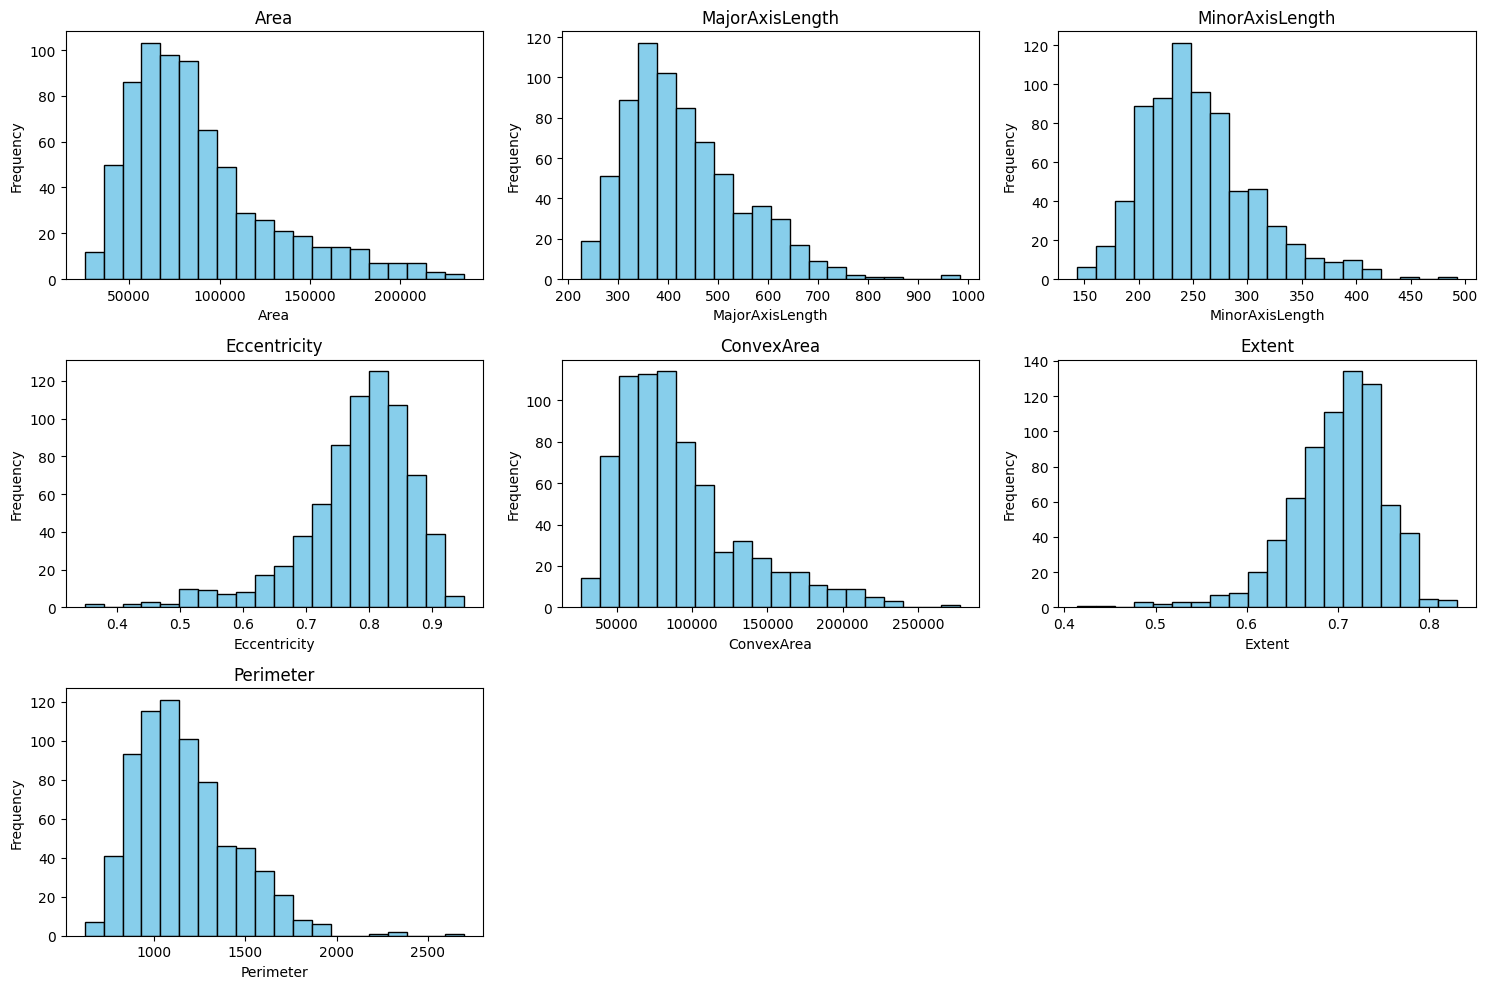

In [20]:
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# --- 1. Plot Histograms ---
plt.figure(figsize=(15, 10))
for i, col in enumerate(X.columns):
    plt.subplot(3, 3, i + 1)
    plt.hist(X[col], bins=20, color='skyblue', edgecolor='black')
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


# --- 2. Standardize Features ---
scaler = StandardScaler()

# Fit on training set only
scaler.fit(X)

test_df =test_df[X.columns]

# Transform both training and test sets
X_scaled_array = scaler.transform(X)
test_df_scaled_array = scaler.transform(test_df)

# Convert back to DataFrame for better readability (and to keep column names)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)
test_df_scaled = pd.DataFrame(test_df_scaled_array, columns=test_df.columns)



Splitting training data into training and validation set (the code has been provided)

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# --- Verification ---
print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Training target shape: {y_train.shape}")
print(f"Validation target shape: {y_val.shape}")

Training set shape: (576, 7)
Validation set shape: (144, 7)
Training target shape: (576,)
Validation target shape: (144,)


### Decision Tree
From sklearn.tree use DecisionTreeClassifier to build a classification model with default parameters.

In [21]:
from sklearn.tree import DecisionTreeClassifier
### Fit the classifier on the training data
# Please set random_state=30
### WRITE CODE HERE ###

from sklearn.tree import DecisionTreeClassifier

# 1. Initialize the classifier
# We use default parameters, but set random_state=30 for reproducibility
clf = DecisionTreeClassifier(random_state=30)

# 2. Fit the classifier on the training data
clf.fit(X_train, y_train)

# --- Verification ---
print("Model trained successfully.")
print(clf)


Model trained successfully.
DecisionTreeClassifier(random_state=30)


In [24]:
### Make predictions on the training data

# Make predictions on the training data
y_pred_train = clf.predict(X_train)

# --- Verification ---
# Display the first 10 predictions
print("First 10 predictions on training data:")
print(y_pred_train[:10])

# Compare with first 10 actual labels
print("\nFirst 10 actual labels (training data):")
print(y_train[:10].values)

First 10 predictions on training data:
[0 1 1 1 0 1 0 1 1 1]

First 10 actual labels (training data):
[0 1 1 1 0 1 0 1 1 1]


Print accuracy, precision and recall for the predictions made on the training data. 

In [25]:
# Print accuracy, precision and recall for the predictions made on the training data.

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

# 4. Re-make predictions
y_pred_train = clf.predict(X_train)

# 5. Calculate Metrics
train_accuracy = accuracy_score(y_train, y_pred_train)
train_precision = precision_score(y_train, y_pred_train)
train_recall = recall_score(y_train, y_pred_train)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Training Precision: {train_precision:.4f}")
print(f"Training Recall: {train_recall:.4f}")

Training Accuracy: 1.0000
Training Precision: 1.0000
Training Recall: 1.0000


Print accuracy, prediction and recall for the predictions made on the validation data.

In [27]:
### Make predictions on the validation data

# 1. Make predictions on the validation data
y_pred_val = clf.predict(X_val)

# 2. Calculate metrics for the validation set
val_accuracy = accuracy_score(y_val, y_pred_val)
val_precision = precision_score(y_val, y_pred_val)
val_recall = recall_score(y_val, y_pred_val)

print("--- Validation Set Metrics ---")
print(f"Accuracy:  {val_accuracy:.4f}")
print(f"Precision: {val_precision:.4f}")
print(f"Recall:    {val_recall:.4f}")


--- Validation Set Metrics ---
Accuracy:  0.8125
Precision: 0.7812
Recall:    0.7937


Plot ROC curve and obtain AUC for predictions on the validation data.

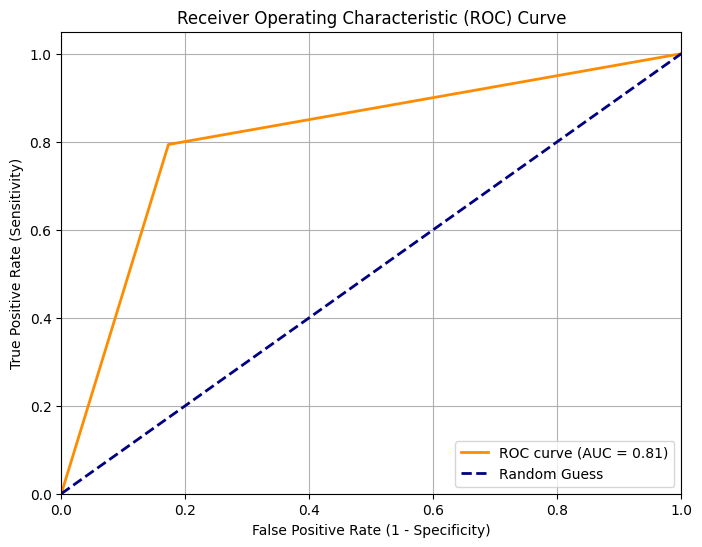

In [20]:
# Plot the ROC curve by giving appropriate names for title and axes. 

### WRITE CODE HERE

from sklearn.metrics import roc_curve
import sklearn.metrics as metrics
import matplotlib.pyplot as plt


from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# 1. Get probability predictions for the positive class (Besni = 1)
# predict_proba returns [prob_class_0, prob_class_1]
y_pred_proba = clf.predict_proba(X_val)[:, 1]

# 2. Calculate False Positive Rate (fpr) and True Positive Rate (tpr)
fpr, tpr, thresholds = roc_curve(y_val, y_pred_proba)

# 3. Calculate Area Under Curve (AUC)
roc_auc = auc(fpr, tpr)

# 4. Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


Q. Based on the scores for training set and validation set, explain the performance of the above model in terms of bias and variance.<br>

Ans - Model is overfitting. we used the DecisionTreeClassifier with default parameters. By default, sklearn allows the tree to grow until every leaf is pure (contains only one class). This creates a highly complex tree that captures every outlier in the training data, resulting in low bias but high variance.

### Random Forest


Decision Trees have low predictive power compared to other methods due to high variance. Random Forest increases prediction power at the expense of decreased interpretability. 


From sklearn.ensemble use RandomForestClassifier to build a classification model with default parameters.

In [28]:
from sklearn.ensemble import RandomForestClassifier
### Fit the classifier on the training data
# Please set random_state=30
### WRITE CODE HERE ###


# 1. Initialize the classifier
# We use default parameters, but set random_state=30 for reproducibility
rf_clf = RandomForestClassifier(random_state=30)

# 2. Fit the classifier on the training data
rf_clf.fit(X_train, y_train)

# --- Verification ---
print("Random Forest model trained successfully.")
print(rf_clf)


Random Forest model trained successfully.
RandomForestClassifier(random_state=30)


In [30]:
### Make predictions on the training data


# 3. Make predictions on the training data
y_pred_train = rf_clf.predict(X_train)



Print accuracy, precision and recall for the predictions made on the training data.

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Calculate and print metrics
print("Training Accuracy:", accuracy_score(y_train, y_pred_train))
print("Training Precision:", precision_score(y_train, y_pred_train))
print("Training Recall:", recall_score(y_train, y_pred_train))

Training Accuracy: 1.0
Training Precision: 1.0
Training Recall: 1.0


In [32]:
### Make predictions on the validation data
### WRITE CODE HERE ###

# 4. Make predictions on the validation data
y_pred_val = rf_clf.predict(X_val)


Print accuracy, prediction and recall for the predictions made on the validation data.

In [33]:
### WRITE CODE HERE ###
# Print metrics for the validation data
print("\nValidation Accuracy:", accuracy_score(y_val, y_pred_val))
print("Validation Precision:", precision_score(y_val, y_pred_val))
print("Validation Recall:", recall_score(y_val, y_pred_val))


Validation Accuracy: 0.8680555555555556
Validation Precision: 0.8548387096774194
Validation Recall: 0.8412698412698413


Plot ROC curve and obtain AUC for the validation predictions

Validation AUC: 0.9119


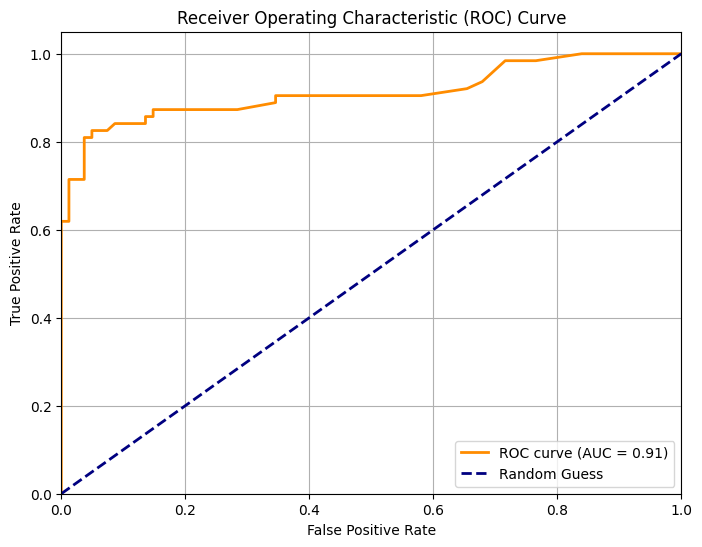

In [35]:
# Plot the ROC curve by giving appropriate names for title and axes. 

### WRITE CODE HERE

from sklearn.metrics import roc_curve, auc
import sklearn.metrics as metrics
import matplotlib.pyplot as plt


# 1. Get predicted probabilities for positive class (Besni = 1)
y_pred_val_proba = rf_clf.predict_proba(X_val)[:, 1]

# 2. Compute ROC curve values
fpr, tpr, thresholds = roc_curve(y_val, y_pred_val_proba)

# 3. Compute AUC
roc_auc = auc(fpr, tpr)

print(f"Validation AUC: {roc_auc:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Q. Based on the scores for training set and validation set, explain the performance of the above model in terms of bias and variance. Is the Random Forest model better or worse than the Decision Tree model? Explain why you think the performance may have improved or deteriorated. 

Ans- Random forest is better. It brings in some randomness to keep trees from being overfit too specifically. 

## Hyperparameters

"Model tuning" refers to model adjustments to better fit the data, which is separate from "fitting" or "training" the model.

There are aspects of some models that are user specified. For example, when using a random forest (which is basically an ensemble of decision trees), it is probably a good idea to choose the right number of underlying trees. Too many and the model might overfit, and too few and the model might not be able to properly learn the data. Parameters such as these are referred to as "hyperparameters" or "free parameters", as the values for these are determined by the user and not the algorithm.

A quick and efficient way to optimize hyperparameters is to perform Grid Search over different values of the parameters. 

In [29]:
from sklearn.model_selection import GridSearchCV

In [36]:
# In the below dictionary, fill in the list of values that you want to try out for each parameter
# Refer to the descriptions in sklearn.ensemble.RandomForestClassifier's doc to understand what the parameters depict
from sklearn.model_selection import GridSearchCV
# 1. Define the parameter grid
param_grid = {
    'max_depth': [10, 20, 30, None],        # Maximum depth of the tree
    'max_features': ['sqrt'],               # Number of features to consider at each split
    'min_samples_leaf': [1, 2, 4],          # Min samples required at a leaf node
    'min_samples_split': [2, 5, 10],        # Min samples required to split a node
    'n_estimators': [50, 100, 200]          # Number of trees in the forest
}

In [ ]:
rf = RandomForestClassifier(random_state=30)

grid_search = GridSearchCV(estimator = rf, scoring='precision', param_grid = param_grid, 
                          cv = 3, n_jobs = -1, verbose = 2)

In [39]:
### Fit on the training data with all sets of parameters.

# 4. Fit the Grid Search to the training data
print("Starting Grid Search...")
grid_search.fit(X_train, y_train)

# --- Results ---
print("\nGrid Search Complete!")
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Precision Score: {grid_search.best_score_:.4f}")

Starting Grid Search...
Fitting 3 folds for each of 108 candidates, totalling 324 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.1s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.1s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.1s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.3s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.3s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.3s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   0.5s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=1, min_samples_sp

Display the parameters of the best model.

In [40]:
# Print the best parameters
# 5. Display all parameters of the best model
print("\nGrid Search Complete!")
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Precision Score: {grid_search.best_score_:.4f}")


Grid Search Complete!
Best Parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 50}
Best Precision Score: 0.8907


In [36]:
# Print the best score
best_rf = grid_search.best_estimator_
print(f"Best score obtained: {grid_search.best_score_}")
print("\nFull parameters of the best model:")
print(best_rf.get_params())

Best score obtained: 0.8907407407407407

Full parameters of the best model:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 20, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 5, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 50, 'n_jobs': None, 'oob_score': False, 'random_state': 30, 'verbose': 0, 'warm_start': False}


In [41]:
### Using the best model, do the following:
### Make predictions on the training set and display accuracy, precision and recall.
### Make predictions on the validation set and display accuracy, precision and recall.

### Using the best model, do the following:
### Make predictions on the training set and display accuracy, precision and recall.
### WRITE CODE HERE ###


### Make predictions on the validation set and display accuracy, precision and recall. 
### WRITE CODE HERE ###

from sklearn.metrics import accuracy_score, precision_score, recall_score

# 1. Retrieve the best model from the completed grid search
best_rf = grid_search.best_estimator_

# --- Evaluation on Training Data ---
print("\n--- Best Model Performance: Training Set ---")
y_pred_train_best = best_rf.predict(X_train)

print(f"Accuracy:  {accuracy_score(y_train, y_pred_train_best):.4f}")
print(f"Precision: {precision_score(y_train, y_pred_train_best):.4f}")
print(f"Recall:    {recall_score(y_train, y_pred_train_best):.4f}")

# --- Evaluation on Validation Data ---
print("\n--- Best Model Performance: Validation Set ---")
y_pred_val_best = best_rf.predict(X_val)

print(f"Accuracy:  {accuracy_score(y_val, y_pred_val_best):.4f}")
print(f"Precision: {precision_score(y_val, y_pred_val_best):.4f}")
print(f"Recall:    {recall_score(y_val, y_pred_val_best):.4f}")



--- Best Model Performance: Training Set ---
Accuracy:  0.9670
Precision: 0.9797
Recall:    0.9571

--- Best Model Performance: Validation Set ---
Accuracy:  0.8750
Precision: 0.8571
Recall:    0.8571


Validation AUC (Best Model): 0.9093


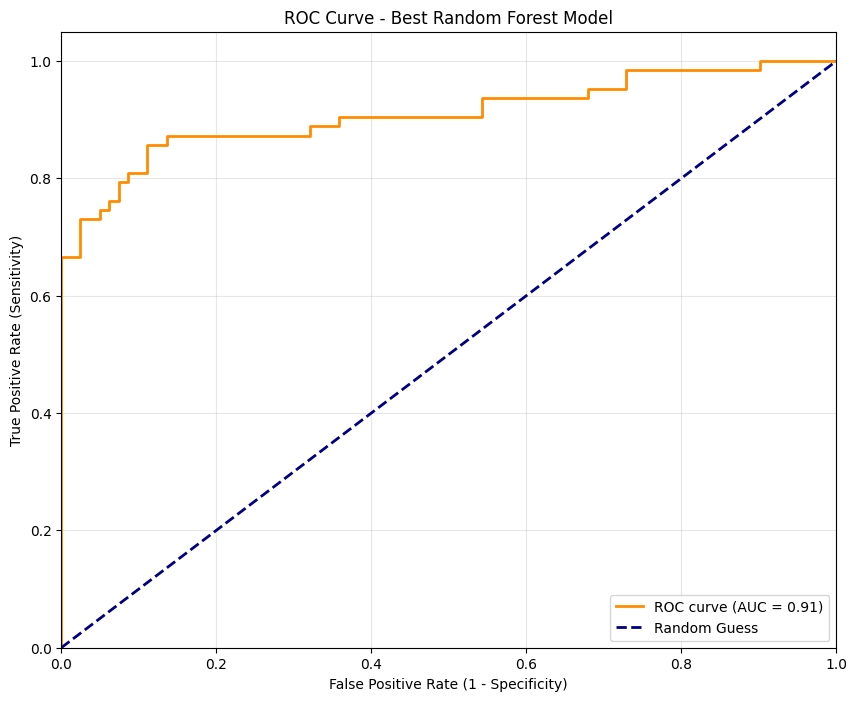

In [42]:
# Plot the ROC curve on validation set by giving appropriate names for title and axes. 

### WRITE CODE HERE

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 1. Get probability predictions for the positive class (Besni = 1)
# Note: We use best_rf (the model found by GridSearchCV)
y_pred_proba_best = best_rf.predict_proba(X_val)[:, 1]

# 2. Calculate False Positive Rate (fpr) and True Positive Rate (tpr)
fpr, tpr, thresholds = roc_curve(y_val, y_pred_proba_best)

# 3. Calculate Area Under Curve (AUC)
roc_auc = auc(fpr, tpr)

print(f"Validation AUC (Best Model): {roc_auc:.4f}")

# 4. Plot the ROC Curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')

# Set limits and labels
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve - Best Random Forest Model')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()



#### Test
Choose the best hyperparameter values from the previous section. Use this random forest model to make predictions on test set.

In [43]:
# Construct your final random forest using the best hyperparameters obtained above

# return the prediction as "y_pred2"

# --- 5. Final Prediction on Test Data ---
# Using the best hyperparameters (contained in best_rf) to predict on the test set.
# Note: 'test_df_scaled' was created in the Data Preprocessing step.

# Make predictions on the test set
y_pred2 = best_rf.predict(test_df_scaled)

# Display the predictions
print("\n--- Final Predictions on Test Set (y_pred2) ---")
print(y_pred2)


--- Final Predictions on Test Set (y_pred2) ---
[0 1 1 1 0 0 0 0 1 0 0 1 1 0 0 0 0 1 1 0 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 0
 1 1 1 0 0 0 0 0 1 1 0 0 0 1 1 0 1 0 0 1 1 1 0 1 0 1 1 1 1 0 0 0 1 1 0 1 0
 1 0 1 0 1 0 1 0 1 0 0 0 0 1 0 1 1 0 1 0 1 1 0 1 1 0 0 0 0 0 1 0 0 0 0 0 1
 1 0 1 1 1 0 1 1 0 1 1 1 0 0 0 0 0 1 0 0 0 0 1 0 1 1 0 0 0 0 1 0 1 0 1 1 0
 0 1 1 0 1 1 1 1 1 1 1 1 0 0 1 0 1 1 0 1 0 1 1 0 1 0 0 0 0 1 1 1]


In [ ]:
#end